# Mini-Project — Wikipedia Topic Graph

**Domain:** Artificial Intelligence  
**Seeds:** AI, Machine learning, Deep learning, Neural network, Natural language processing

Pipeline: crawl → 3 graphs (article / entity / keyword) → structural + centrality + community + path analysis → dashboard + interactive HTML → report.

In [1]:
import sys, os, pathlib, time, warnings
warnings.filterwarnings("ignore")

# --- Find project root (the folder containing src/) ---
here = pathlib.Path.cwd().resolve()
PROJECT_ROOT = next((r for r in [here, *here.parents] if (r / "src").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError(
        f"Could not find 'src/' above {here}.\n"
        "Expected: miniproject_yassir/src/... with the notebook in miniproject_yassir/notebooks/"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
(PROJECT_ROOT / "data").mkdir(exist_ok=True)
(PROJECT_ROOT / "outputs").mkdir(exist_ok=True)

# --- Imports ---
from src import config, crawl, graphs, analysis, viz
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import Image, display as _display

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("Imports OK   :", [m.__name__ for m in (config, crawl, graphs, analysis, viz)])
print("Domain       :", config.DOMAIN)
print("Seeds        :", config.SEED_ARTICLES)

PROJECT_ROOT : D:\EIDIA 5\Knowledge\VsCode_Knowledge\euromed-graph-course\miniproject_yassir
Imports OK   : ['src.config', 'src.crawl', 'src.graphs', 'src.analysis', 'src.viz']
Domain       : AI
Seeds        : ['Artificial intelligence', 'Machine learning', 'Deep learning', 'Neural network', 'Natural language processing']


## Part 1 — Data Collection

BFS crawl from seed articles. First 1 000 words per article, up to 18 links followed per article, 0.35 s polite delay. The crawler is resumable — re-running keeps expanding the cached JSON.

In [2]:
t0 = time.time()
corpus = crawl.crawl()
assert len(corpus) >= config.MIN_ARTICLES, (
    f"Only {len(corpus)} articles collected (min {config.MIN_ARTICLES}). "
    "Re-run this cell to keep expanding."
)

avg_words = sum(len(t.split()) for t in corpus.values()) / len(corpus)
print(f"\n✓ {len(corpus)} articles  |  avg words: {avg_words:.0f}  |  {time.time()-t0:.1f}s")

preview = pd.DataFrame(
    [(title, len(text.split())) for title, text in list(corpus.items())[:10]],
    columns=["title", "word_count"],
)
preview

[resume] 200 articles already cached


articles: 100%|██████████| 200/200 [00:00<?, ?it/s]

saved 200 articles → data/wikipedia_articles.json

✓ 200 articles  |  avg words: 824  |  0.0s


,title,word_count
0,Artificial intelligence,1000
1,Machine learning,1000
2,Deep learning,1000
3,Neural network,767
4,Natural language processing,1000
5,Blended artificial intelligence,350
6,AI Overviews,1000
7,Foundation model,1000
8,AI anthropomorphism,1000
9,Rest of World,774


## Part 2 — Graph Construction

Three complementary graphs:
- **Article similarity** — TF-IDF + cosine ≥ 0.12.
- **Entity co-occurrence** — spaCy NER (PERSON, ORG, GPE, PRODUCT, WORK_OF_ART, EVENT), edges if entities share a sentence. Kept if in ≥ 2 articles and degree ≥ 2.
- **Keyword co-occurrence** — alphabetic tokens, length ≥ 4, non-stop, sliding window of 5 → edges with weight ≥ 5.

In [3]:
t0 = time.time()

G_art = graphs.build_article_graph(corpus)
G_ent = graphs.build_entity_graph(corpus)
G_kw  = graphs.build_keyword_graph(corpus)

summary = pd.DataFrame({
    "graph":  ["article", "entity", "keyword"],
    "nodes":  [G_art.number_of_nodes(), G_ent.number_of_nodes(), G_kw.number_of_nodes()],
    "edges":  [G_art.number_of_edges(), G_ent.number_of_edges(), G_kw.number_of_edges()],
})
print(f"✓ Built in {time.time()-t0:.1f}s")
summary

✓ Built in 20.3s


,graph,nodes,edges
0,article,200,847
1,entity,435,1431
2,keyword,13370,90845


## Part 3 — Graph Analysis

### 3.1 Structural statistics

In [4]:
stats = pd.DataFrame({
    "article": analysis.structural_stats(G_art),
    "entity" : analysis.structural_stats(G_ent),
    "keyword": analysis.structural_stats(G_kw),
})
stats = stats.round(4)
stats.index.name = "metric"
stats

,article,entity,keyword
metric,,,
nodes,200.0000,435.0000,13370
edges,847.0000,1431.0000,90845
density,0.0426,0.0152,0.001016
components,31.0000,4.0000,1
lcc_size,168.0000,428.0000,13370
avg_degree,8.4700,6.5793,13.589379
diameter,10.0000,8.0000,Skipped (Too large)
avg_clustering,0.4141,0.5498,0.206741
avg_path,3.5757,3.6018,Skipped (Too large)


### 3.2 Centrality analysis (entity graph)

In [5]:
cent = analysis.centrality_table(G_ent)
cent.to_csv(PROJECT_ROOT / "outputs" / "entity_centrality_results.csv", index=False)

print("Top 10 by PageRank:")
_display(cent.head(10))

print("\nTop 10 by Betweenness:")
_display(cent.sort_values("betweenness", ascending=False).head(10))

print("\nTop 10 by Degree:")
_display(cent.sort_values("degree_cent", ascending=False).head(10))

print("\nTop 10 by Closeness:")
_display(cent.sort_values("closeness", ascending=False).head(10))

Top 10 by PageRank:


,entity,type,degree_cent,betweenness,closeness,pagerank
0,Google,ORG,0.163594,0.150062,0.348931,0.032089
1,the United States,GPE,0.131336,0.181852,0.380537,0.017020
2,OpenAI,GPE,0.085253,0.059353,0.334485,0.014784
3,China,GPE,0.085253,0.055679,0.324412,0.013120
4,U.S.,GPE,0.089862,0.108083,0.353036,0.012316
5,New York,GPE,0.096774,0.108255,0.352444,0.011390
6,Claude,PERSON,0.082949,0.055492,0.336359,0.009306
7,Microsoft,ORG,0.052995,0.015344,0.312352,0.009204
8,Schmidt,PERSON,0.064516,0.063245,0.321187,0.008781
9,The New York Times,ORG,0.062212,0.086871,0.324412,0.008426



Top 10 by Betweenness:


,entity,type,degree_cent,betweenness,closeness,pagerank
1,the United States,GPE,0.131336,0.181852,0.380537,0.017020
0,Google,ORG,0.163594,0.150062,0.348931,0.032089
5,New York,GPE,0.096774,0.108255,0.352444,0.011390
4,U.S.,GPE,0.089862,0.108083,0.353036,0.012316
9,The New York Times,ORG,0.062212,0.086871,0.324412,0.008426
8,Schmidt,PERSON,0.064516,0.063245,0.321187,0.008781
13,Simon,PERSON,0.066820,0.059429,0.336359,0.007122
2,OpenAI,GPE,0.085253,0.059353,0.334485,0.014784
21,United States,GPE,0.050691,0.055929,0.333688,0.005690
3,China,GPE,0.085253,0.055679,0.324412,0.013120



Top 10 by Degree:


,entity,type,degree_cent,betweenness,closeness,pagerank
0,Google,ORG,0.163594,0.150062,0.348931,0.032089
1,the United States,GPE,0.131336,0.181852,0.380537,0.017020
5,New York,GPE,0.096774,0.108255,0.352444,0.011390
4,U.S.,GPE,0.089862,0.108083,0.353036,0.012316
2,OpenAI,GPE,0.085253,0.059353,0.334485,0.014784
3,China,GPE,0.085253,0.055679,0.324412,0.013120
6,Claude,PERSON,0.082949,0.055492,0.336359,0.009306
13,Simon,PERSON,0.066820,0.059429,0.336359,0.007122
8,Schmidt,PERSON,0.064516,0.063245,0.321187,0.008781
9,The New York Times,ORG,0.062212,0.086871,0.324412,0.008426



Top 10 by Closeness:


,entity,type,degree_cent,betweenness,closeness,pagerank
1,the United States,GPE,0.131336,0.181852,0.380537,0.017020
4,U.S.,GPE,0.089862,0.108083,0.353036,0.012316
5,New York,GPE,0.096774,0.108255,0.352444,0.011390
0,Google,ORG,0.163594,0.150062,0.348931,0.032089
6,Claude,PERSON,0.082949,0.055492,0.336359,0.009306
13,Simon,PERSON,0.066820,0.059429,0.336359,0.007122
2,OpenAI,GPE,0.085253,0.059353,0.334485,0.014784
21,United States,GPE,0.050691,0.055929,0.333688,0.005690
117,Yale University,ORG,0.023041,0.022989,0.327957,0.002525
46,Harvard University,ORG,0.041475,0.027095,0.327701,0.003887


### 3.3 Community detection

In [6]:
greedy_map,  greedy_parts  = analysis.communities_greedy(G_ent)
louvain_map, louvain_parts = analysis.communities_louvain(G_ent)

print(f"Greedy Modularity : {len(greedy_parts)} communities")
print(f"Louvain           : {len(louvain_parts)} communities")

_pr_index = cent.set_index("entity")["pagerank"]

def _top_members(parts, k=5, n=5):
    rows = []
    for cid, members in enumerate(sorted(parts, key=len, reverse=True)[:k]):
        ranked = sorted(members, key=lambda x: _pr_index.get(x, 0), reverse=True)
        rows.append({"community": cid, "size": len(members), "top_5": ranked[:n]})
    return pd.DataFrame(rows)

print("\nGreedy — top 5 communities:")
_display(_top_members(greedy_parts))

print("\nLouvain — top 5 communities:")
_display(_top_members(louvain_parts))

Greedy Modularity : 19 communities
Louvain           : 17 communities

Greedy — top 5 communities:


,community,size,top_5
0,0,83,"[the United States, China, U.S., India, the United Kingdom]"
1,1,72,"[Google, OpenAI, Microsoft, Schmidt, Gemini]"
2,2,61,"[California, Simon, Washington, United States, John]"
3,3,48,"[New York, The New York Times, Times, Gödel, BuzzFeed News]"
4,4,44,"[AlexNet, Demis Hassabis, Ilya Sutskever, Ph.D., Geoffrey Hinton]"



Louvain — top 5 communities:


,community,size,top_5
0,0,74,"[Google, OpenAI, Microsoft, Schmidt, Gemini]"
1,1,54,"[the United States, China, U.S., the United Kingdom, the Soviet Union]"
2,2,48,"[New York City, Washington, United States, NPR, Boston]"
3,3,47,"[References External, Yale, Ph.D., Berkeley, Warren McCulloch]"
4,4,43,"[The New York Times, Times, BuzzFeed News, The New-York Times, The Intercept]"


### 3.4 Path analysis — six degrees of separation

In [7]:
paths = analysis.top_pairs_paths(G_ent, k=10, n_pairs=6)

if not paths:
    print("No paths found — LCC likely has < 2 nodes. Relax thresholds in config.py.")
else:
    df_paths = pd.DataFrame([{
        "from":   p["from"],
        "to":     p["to"],
        "length": p["length"],
        "path":   " → ".join(p["path"]),
    } for p in paths])
    _display(df_paths)
    print(f"\nAverage shortest path between top-10 degree nodes: {df_paths['length'].mean():.2f}")

,from,to,length,path
0,Google,the United States,1,Google → the United States
1,Google,New York,2,Google → PDF → New York
2,Google,U.S.,1,Google → U.S.
3,Google,China,1,Google → China
4,Google,OpenAI,1,Google → OpenAI
5,Google,Claude,2,Google → Gemini → Claude



Average shortest path between top-10 degree nodes: 1.33


## Part 4 — Visualization

Static 2×2 dashboard + interactive pyvis graph (entity graph).

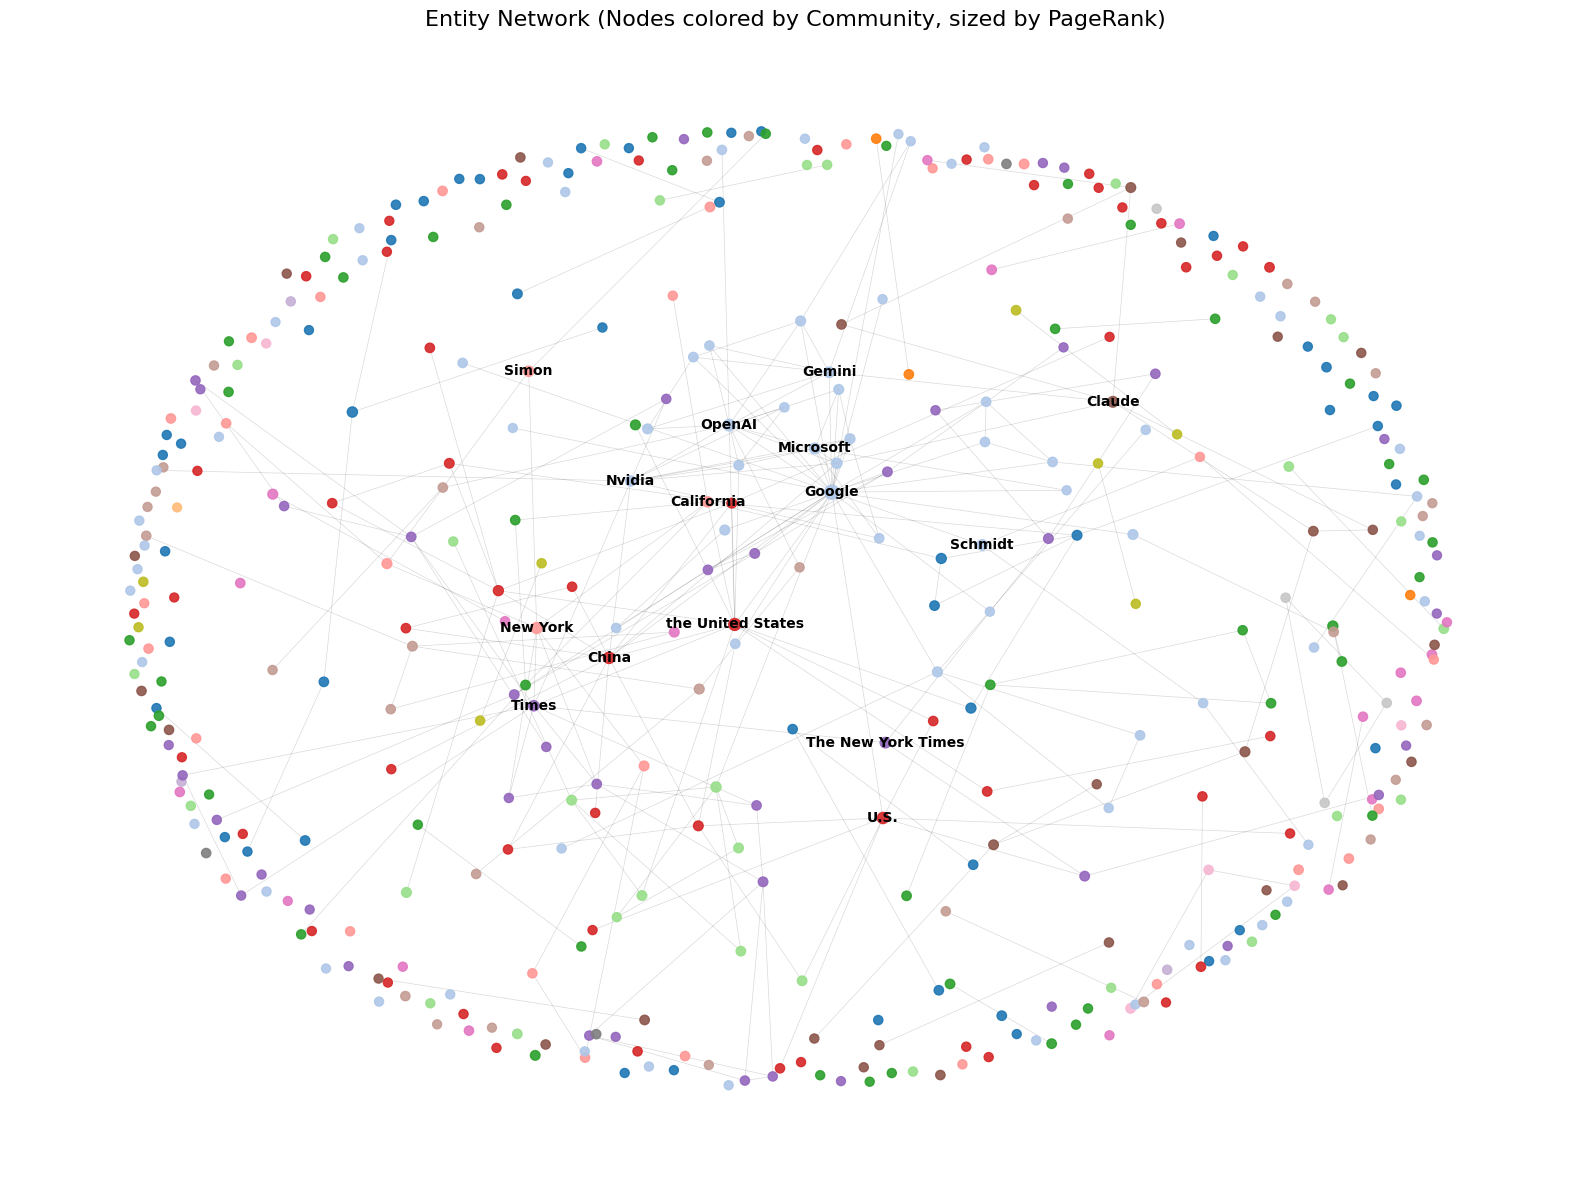

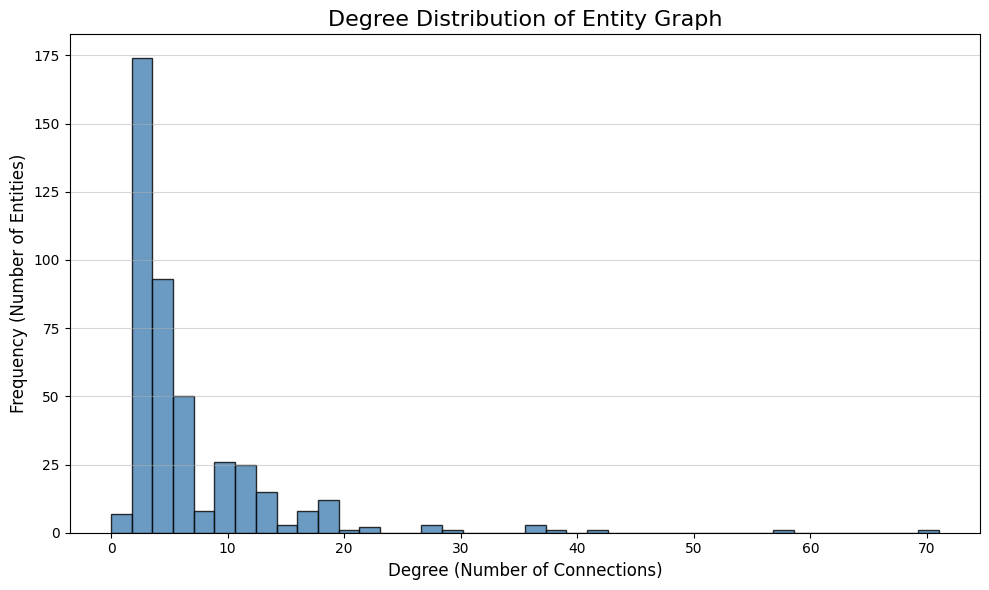

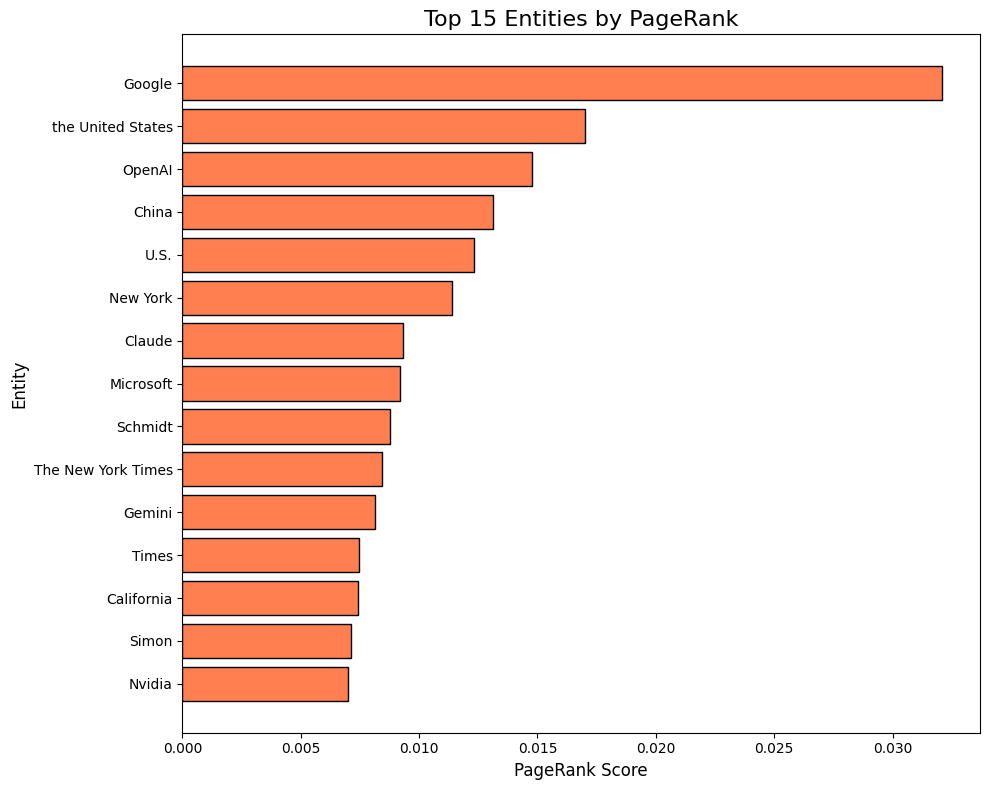

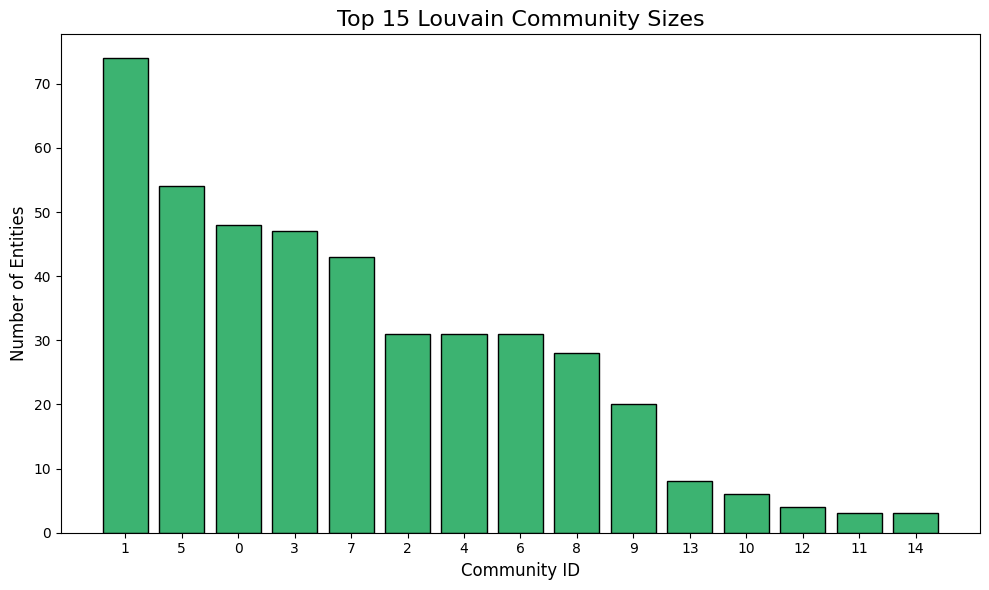

✓ 4 separate high-res plots saved to outputs/ folder!


In [8]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import numpy as np

# Use the same community color map
COMMUNITY_CMAP = plt.cm.tab20

# ==========================================
# PLOT 1: Entity Network (Full Size)
# ==========================================
plt.figure(figsize=(16, 12))

# Filter edges to remove clutter (only keep edges with weight >= 2)
viz_G = G_ent.copy()
viz_G.remove_edges_from([(u, v, d) for u, v, d in viz_G.edges(data=True) if d.get("weight", 1) < 2])

# Better layout
pos = nx.spring_layout(viz_G, seed=42, k=0.8, iterations=100)
pr = cent.set_index("entity")["pagerank"]
node_colors = [COMMUNITY_CMAP(louvain_map.get(n, 0) % 20) for n in viz_G.nodes]
node_sizes = [40 + 2000 * pr.get(n, 0) for n in viz_G.nodes]

nx.draw_networkx_edges(viz_G, pos, alpha=0.15, width=0.5)
nx.draw_networkx_nodes(viz_G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9)
top15 = pr.sort_values(ascending=False).head(15).index
labels = {n: n for n in top15 if n in viz_G.nodes}
nx.draw_networkx_labels(viz_G, pos, labels, font_size=10, font_weight="bold")

plt.title("Entity Network (Nodes colored by Community, sized by PageRank)", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "plot_1_network.png", dpi=200)
plt.show()

# ==========================================
# PLOT 2: Degree Distribution
# ==========================================
plt.figure(figsize=(10, 6))
degs = [d for _, d in G_ent.degree()]
plt.hist(degs, bins=40, color="steelblue", edgecolor="black", alpha=0.8)
plt.title("Degree Distribution of Entity Graph", fontsize=16)
plt.xlabel("Degree (Number of Connections)", fontsize=12)
plt.ylabel("Frequency (Number of Entities)", fontsize=12)
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "plot_2_degree_dist.png", dpi=200)
plt.show()

# ==========================================
# PLOT 3: Top 15 Entities by PageRank
# ==========================================
plt.figure(figsize=(10, 8))
top15_df = cent.head(15).iloc[::-1]
plt.barh(top15_df["entity"], top15_df["pagerank"], color="coral", edgecolor="black")
plt.title("Top 15 Entities by PageRank", fontsize=16)
plt.xlabel("PageRank Score", fontsize=12)
plt.ylabel("Entity", fontsize=12)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "plot_3_top_pagerank.png", dpi=200)
plt.show()

# ==========================================
# PLOT 4: Community Sizes
# ==========================================
plt.figure(figsize=(10, 6))
sizes = pd.Series([len(c) for c in louvain_parts]).sort_values(ascending=False).head(15)
plt.bar(sizes.index.astype(str), sizes.values, color="mediumseagreen", edgecolor="black")
plt.title("Top 15 Louvain Community Sizes", fontsize=16)
plt.xlabel("Community ID", fontsize=12)
plt.ylabel("Number of Entities", fontsize=12)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "plot_4_community_sizes.png", dpi=200)
plt.show()

print("✓ 4 separate high-res plots saved to outputs/ folder!")

## Part 5 — Key findings (feeds the report)

In [9]:
print("=" * 70)
print(f"DOMAIN: {config.DOMAIN}")
print("=" * 70)

print(f"\n[Data] {len(corpus)} articles | avg {avg_words:.0f} words")
print(f"[Article graph] {G_art.number_of_nodes()} nodes, {G_art.number_of_edges()} edges, "
      f"density={nx.density(G_art):.4f}")

print("\n[Top 5 entities by PageRank]")
for _, row in cent.head(5).iterrows():
    print(f"  {row['entity']:<28} type={row['type']:<12} pr={row['pagerank']:.4f}")

print(f"\n[Communities] Greedy={len(greedy_parts)}, Louvain={len(louvain_parts)}")
sizes = sorted((len(m) for m in louvain_parts), reverse=True)[:5]
print(f"[Top 5 Louvain community sizes] {sizes}")

if paths:
    print(f"\n[Paths] avg shortest path between top-10 nodes = "
          f"{pd.DataFrame(paths)['length'].mean():.2f}")

print("\n[Entity types present]", cent["type"].value_counts().to_dict())

DOMAIN: AI

[Data] 200 articles | avg 824 words
[Article graph] 200 nodes, 847 edges, density=0.0426

[Top 5 entities by PageRank]
  Google                       type=ORG          pr=0.0321
  the United States            type=GPE          pr=0.0170
  OpenAI                       type=GPE          pr=0.0148
  China                        type=GPE          pr=0.0131
  U.S.                         type=GPE          pr=0.0123

[Communities] Greedy=19, Louvain=17
[Top 5 Louvain community sizes] [74, 54, 48, 47, 43]

[Paths] avg shortest path between top-10 nodes = 1.33

[Entity types present] {'ORG': 172, 'PERSON': 118, 'GPE': 112, 'WORK_OF_ART': 15, 'PRODUCT': 11, 'EVENT': 7}


In [10]:
checks = {
    "articles >= 150"        : len(corpus) >= 150,
    "entity graph non-empty" : G_ent.number_of_nodes() > 0,
    "centrality csv saved"   : (PROJECT_ROOT / "outputs" / "entity_centrality_results.csv").exists(),
    "dashboard png saved"    : (PROJECT_ROOT / "outputs" / "miniproject_dashboard.png").exists(),
    "interactive html saved" : (PROJECT_ROOT / "outputs" / "miniproject_interactive.html").exists(),
    "corpus json saved"      : (PROJECT_ROOT / "data" / "wikipedia_articles.json").exists(),
}
for name, ok in checks.items():
    print(("✓" if ok else "✗"), name)
assert all(checks.values()), "Fix the ✗ items before submitting."
print("\nAll checks passed — notebook is submission-ready.")

✓ articles >= 150
✓ entity graph non-empty
✓ centrality csv saved
✓ dashboard png saved
✓ interactive html saved
✓ corpus json saved

All checks passed — notebook is submission-ready.
